In [1]:
!pip install pandas numpy scikit-learn matplotlib seaborn joblib

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import joblib
import zipfile
import urllib.request
import os

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("All libraries imported successfully!")


All libraries imported successfully!


In [3]:
url = "https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip"

urllib.request.urlretrieve(url, "spam_dataset.zip")

with zipfile.ZipFile("spam_dataset.zip", "r") as zip_ref:
    zip_ref.extractall("spam_data")

df = pd.read_csv(
    "spam_data/SMSSpamCollection",
    sep="\t",
    header=None,
    names=["label", "message"]
)

print("Dataset downloaded successfully!")
print(df.head())


Dataset downloaded successfully!
  label                                            message
0   ham  Go until jurong point, crazy.. Available only ...
1   ham                      Ok lar... Joking wif u oni...
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...
3   ham  U dun say so early hor... U c already then say...
4   ham  Nah I don't think he goes to usf, he lives aro...


In [4]:
print("Dataset Shape:", df.shape)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nCategory Distribution:")
print(df["label"].value_counts())


Dataset Shape: (5572, 2)

Missing Values:
label      0
message    0
dtype: int64

Category Distribution:
label
ham     4825
spam     747
Name: count, dtype: int64


In [5]:
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r'[^a-zA-Z\s]', '', text)
    text = re.sub(r'\s+', ' ', text)
    return text.strip()

df["message"] = df["message"].apply(clean_text)

df["label"] = df["label"].map({
    "ham": 0,
    "spam": 1
})

df.dropna(inplace=True)

print("Text preprocessing completed!")
print(df.head())


Text preprocessing completed!
   label                                            message
0      0  go until jurong point crazy available only in ...
1      0                            ok lar joking wif u oni
2      1  free entry in a wkly comp to win fa cup final ...
3      0        u dun say so early hor u c already then say
4      0  nah i dont think he goes to usf he lives aroun...


In [14]:

X = df["message"]
y = df["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

tfidf = TfidfVectorizer(
    stop_words="english",
    max_features=5000
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("TF-IDF conversion completed!")
print("Training matrix:", X_train_tfidf.shape)
print("Testing matrix:", X_test_tfidf.shape)


TF-IDF conversion completed!
Training matrix: (4457, 5000)
Testing matrix: (1115, 5000)


In [15]:

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])



Training samples: 4457
Testing samples: 1115


In [16]:

model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

model.fit(X_train_tfidf, y_train)

print("Logistic Regression Model Trained Successfully!")



Logistic Regression Model Trained Successfully!


In [17]:

y_pred = model.predict(X_test_tfidf)

accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("MODEL EVALUATION RESULTS")
print("------------------------")

print("Accuracy:", round(accuracy * 100, 2), "%")
print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("F1 Score:", round(f1, 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Ham", "Spam"]
))


MODEL EVALUATION RESULTS
------------------------
Accuracy: 96.5 %
Precision: 1.0
Recall: 0.7383
F1 Score: 0.8494

Classification Report:
              precision    recall  f1-score   support

         Ham       0.96      1.00      0.98       966
        Spam       1.00      0.74      0.85       149

    accuracy                           0.97      1115
   macro avg       0.98      0.87      0.91      1115
weighted avg       0.97      0.97      0.96      1115



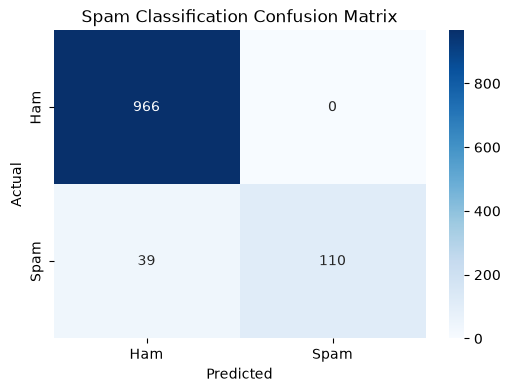

In [18]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Ham", "Spam"],
    yticklabels=["Ham", "Spam"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Spam Classification Confusion Matrix")

plt.show()


In [19]:
joblib.dump(
    {
        "model": model,
        "tfidf": tfidf
    },
    "spam_classifier_model.pkl"
)

print("Model exported successfully!")


Model exported successfully!


In [20]:
def predict_spam(message):

    cleaned_message = clean_text(message)

    message_tfidf = tfidf.transform([cleaned_message])

    prediction = model.predict(message_tfidf)

    if prediction[0] == 1:
        return "SPAM"
    else:
        return "HAM"

# Test messages

test_messages = [
    "Congratulations! You have won a free prize. Claim now!",
    "Hey, are we meeting today?",
    "URGENT! You have won a cash reward. Call now!",
    "Please send me the assignment notes."
]

for message in test_messages:

    result = predict_spam(message)

    print("Message:", message)
    print("Prediction:", result)
    print("------------------------------")


Message: Congratulations! You have won a free prize. Claim now!
Prediction: SPAM
------------------------------
Message: Hey, are we meeting today?
Prediction: HAM
------------------------------
Message: URGENT! You have won a cash reward. Call now!
Prediction: SPAM
------------------------------
Message: Please send me the assignment notes.
Prediction: HAM
------------------------------


In [21]:
loaded_data = joblib.load("spam_classifier_model.pkl")

loaded_model = loaded_data["model"]
loaded_tfidf = loaded_data["tfidf"]

print("Saved model loaded successfully!")

sample = ["Congratulations! You won a free gift"]

sample_vector = loaded_tfidf.transform(sample)

result = loaded_model.predict(sample_vector)

print("Final Prediction:",
      "SPAM" if result[0] == 1 else "HAM")


Saved model loaded successfully!
Final Prediction: SPAM
